<a href="https://colab.research.google.com/github/Echida/axion-wyzwania/blob/main/wyzwanie3/wyzwanie3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
!pip install qiskit

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.5/9.5 MB 17.8 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.4/2.4 MB 27.0 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3/3 [qiskit]


In [2]:
import qiskit; print(qiskit.__version__)

2.6.2


In [3]:
import numpy as np

rng = np.random.default_rng(0)          # sabit tohum: her çalıştırmada aynı sayılar

X = rng.uniform(0, np.pi, size=(300, 2))  # 300 satır, 2 sütun: [x1, x2], hepsi 0..π
x1 = X[:, 0]                              # 1. sütun
x2 = X[:, 1]                              # 2. sütun

# Kural A: sadece x1'e bak
y_A = np.where(x1 > np.pi/2, 1, -1)

# Kural B: x1 ve x2 π/2'nin aynı tarafındaysa +1, değilse -1
y_B = np.where((x1 > np.pi/2) == (x2 > np.pi/2), 1, -1)

# İlk 200 eğitim, son 100 test
X_train, X_test = X[:200], X[200:]
yA_train, yA_test = y_A[:200], y_A[200:]
yB_train, yB_test = y_B[:200], y_B[200:]

print("İlk 5 nokta:")
for i in range(5):
    print(f"x1={x1[i]:.2f}  x2={x2[i]:.2f}  ->  A={y_A[i]:+d}  B={y_B[i]:+d}")
print("A'da +1 oranı:", np.mean(y_A == 1))
print("B'de +1 oranı:", np.mean(y_B == 1))

İlk 5 nokta:
x1=2.00  x2=0.85  ->  A=+1  B=-1
x1=0.13  x2=0.05  ->  A=-1  B=+1
x1=2.55  x2=2.87  ->  A=+1  B=+1
x1=1.91  x2=2.29  ->  A=+1  B=+1
x1=1.71  x2=2.94  ->  A=+1  B=+1
A'da +1 oranı: 0.57
B'de +1 oranı: 0.4666666666666667


In [4]:
from qiskit import QuantumCircuit
from qiskit.circuit import ParameterVector
from qiskit.quantum_info import SparsePauliOp
from qiskit.primitives import StatevectorEstimator

def build_circuit(L, use_cnot):
    x  = ParameterVector("x", 2)          # veri açıları
    th = ParameterVector("th", 4 * L)     # eğitilen açılar: her katmanda 4 tane
    qc = QuantumCircuit(2)
    qc.ry(x[0], 0)                        # kodlama: x1 -> q0
    qc.ry(x[1], 1)                        # kodlama: x2 -> q1
    for l in range(L):                    # ansatz bloğu L kere tekrarlanır
        t = th[4*l : 4*l + 4]
        qc.ry(t[0], 0)
        qc.ry(t[1], 1)
        if use_cnot:
            qc.cx(0, 1)                   # köprü: kontrol q0, hedef q1
        qc.ry(t[2], 0)
        qc.ry(t[3], 1)
    return qc

Z0 = SparsePauliOp.from_sparse_list([("Z", [0], 1.0)], num_qubits=2)   # sadece q0'ı ölç (slayt 35)
estimator = StatevectorEstimator()                                       # tam (shot'suz) hesap

def f_batch(qc, X, theta):
    # Qiskit parametreleri alfabetik sıralar: önce "th", sonra "x".
    params = np.hstack([np.tile(theta, (len(X), 1)), X])
    result = estimator.run([(qc, Z0, params)]).result()
    return result[0].data.evs            # her nokta için f = <Z0>

print(build_circuit(L=1, use_cnot=True).draw())
print(build_circuit(L=1, use_cnot=False).draw())

     ┌──────────┐┌───────────┐     ┌───────────┐
q_0: ┤ Ry(x[0]) ├┤ Ry(th[0]) ├──■──┤ Ry(th[2]) ├
     ├──────────┤├───────────┤┌─┴─┐├───────────┤
q_1: ┤ Ry(x[1]) ├┤ Ry(th[1]) ├┤ X ├┤ Ry(th[3]) ├
     └──────────┘└───────────┘└───┘└───────────┘
     ┌──────────┐┌───────────┐┌───────────┐
q_0: ┤ Ry(x[0]) ├┤ Ry(th[0]) ├┤ Ry(th[2]) ├
     ├──────────┤├───────────┤├───────────┤
q_1: ┤ Ry(x[1]) ├┤ Ry(th[1]) ├┤ Ry(th[3]) ├
     └──────────┘└───────────┘└───────────┘


In [5]:
def grad_batch(qc, X, theta):
    # Parameter-shift (slayt 39): her θ_j için +π/2 ve -π/2 kaydırılmış iki devre
    P = len(theta)
    shifted = []
    for j in range(P):
        plus = theta.copy();  plus[j]  += np.pi/2
        minus = theta.copy(); minus[j] -= np.pi/2
        shifted += [plus, minus]
    rows = [np.hstack([t, x]) for t in shifted for x in X]     # 2P × N devre, tek seferde
    evs = estimator.run([(qc, Z0, np.array(rows))]).result()[0].data.evs
    evs = evs.reshape(2*P, len(X))
    return (evs[0::2] - evs[1::2]) / 2                            # [f(θ+π/2) - f(θ-π/2)] / 2

def accuracy(qc, X, y, theta):
    return np.mean(np.sign(f_batch(qc, X, theta)) == y)          # ŷ = sign(f) (slayt 33)

def train(L, use_cnot, X_tr, y_tr, X_te, y_te, seed, epochs=50, lr=0.1):
    qc = build_circuit(L, use_cnot)
    theta = np.random.default_rng(seed).uniform(-0.1, 0.1, 4*L)  # küçük başlangıç açıları
    history = {"loss": [], "train_acc": [], "test_acc": []}
    for epoch in range(epochs):
        f = f_batch(qc, X_tr, theta)                              # ileri geçiş
        g = grad_batch(qc, X_tr, theta)                           # her θ için eğim
        grad_L = (2 * (f - y_tr) * g).mean(axis=1)                # MSE'nin gradyanı (slayt 44)
        theta = theta - lr * grad_L                               # güncelleme (slayt 45)
        history["loss"].append(np.mean((f - y_tr)**2))
        history["train_acc"].append(np.mean(np.sign(f) == y_tr))
        history["test_acc"].append(accuracy(qc, X_te, y_te, theta))
    return theta, history

In [6]:
import time

datasets = {"A": (yA_train, yA_test), "B": (yB_train, yB_test)}
results = {}   # anahtar: (L, kural, cnot) -> 5 tohumun eğitim geçmişleri

def run_experiment(L, seeds=range(5), epochs=50):
    for rule, (y_tr, y_te) in datasets.items():          # Kural A ve B
        for use_cnot in (False, True):                    # CNOT'suz ve CNOT'lu
            start = time.time()
            runs = []
            for seed in seeds:                            # 5 farklı başlangıç
                theta, hist = train(L, use_cnot, X_train, y_tr, X_test, y_te, seed, epochs=epochs)
                runs.append(hist)
            results[(L, rule, use_cnot)] = runs
            final = [h["test_acc"][-1] for h in runs]     # son epoch'taki test doğruluğu
            name = "CNOT'lu " if use_cnot else "CNOT'suz"
            print(f"L={L}  Kural {rule}  {name}:  test doğruluğu = {np.mean(final):.0%} ± {np.std(final):.0%}"
                  f"   ({time.time()-start:.0f} sn)")

run_experiment(L=1)

L=1  Kural A  CNOT'suz:  test doğruluğu = 100% ± 0%   (327 sn)
L=1  Kural A  CNOT'lu :  test doğruluğu = 95% ± 3%   (352 sn)
L=1  Kural B  CNOT'suz:  test doğruluğu = 52% ± 1%   (334 sn)
L=1  Kural B  CNOT'lu :  test doğruluğu = 62% ± 7%   (360 sn)


In [7]:
run_experiment(L=3)

L=3  Kural A  CNOT'suz:  test doğruluğu = 100% ± 0%   (1549 sn)
L=3  Kural A  CNOT'lu :  test doğruluğu = 97% ± 2%   (1694 sn)
L=3  Kural B  CNOT'suz:  test doğruluğu = 46% ± 1%   (1461 sn)
L=3  Kural B  CNOT'lu :  test doğruluğu = 97% ± 0%   (1694 sn)


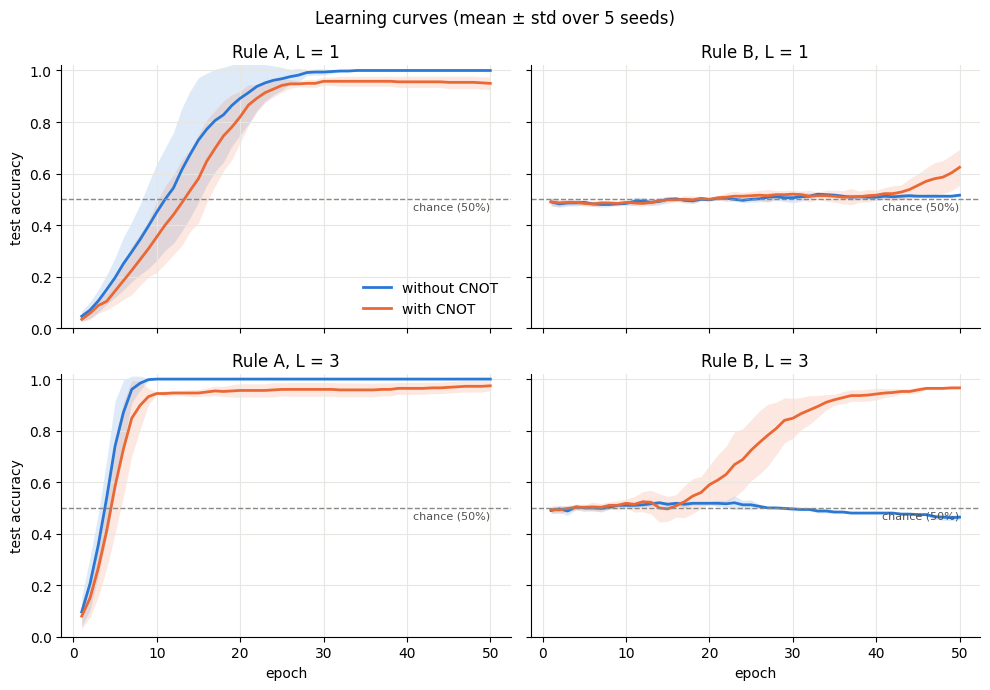

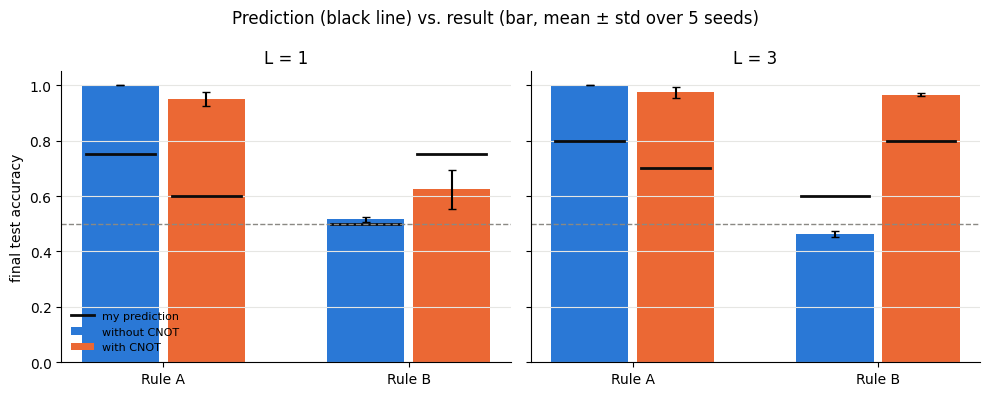

In [8]:
import matplotlib.pyplot as plt

COL = {False: "#2a78d6", True: "#eb6834"}          # CNOT'suz: mavi, CNOT'lu: turuncu
LBL = {False: "without CNOT", True: "with CNOT"}
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.color": "#e6e6e3", "grid.linewidth": 0.8,
                     "font.size": 10})

# ---- Grafik 1: öğrenme eğrileri (test doğruluğu, epoch'a göre) ----
fig, axes = plt.subplots(2, 2, figsize=(10, 7), sharex=True, sharey=True)
for i, L in enumerate((1, 3)):
    for j, rule in enumerate(("A", "B")):
        ax = axes[i, j]
        for use_cnot in (False, True):
            acc = np.array([h["test_acc"] for h in results[(L, rule, use_cnot)]])  # (5 tohum, 50 epoch)
            mean, std = acc.mean(0), acc.std(0)
            ep = np.arange(1, len(mean) + 1)
            ax.plot(ep, mean, color=COL[use_cnot], lw=2, label=LBL[use_cnot])
            ax.fill_between(ep, mean - std, mean + std, color=COL[use_cnot], alpha=0.15, lw=0)
        ax.axhline(0.5, color="#8a8984", lw=1, ls="--")
        ax.text(50, 0.49, "chance (50%)", ha="right", va="top", color="#52514e", fontsize=8)
        ax.set_title(f"Rule {rule}, L = {L}")
        ax.set_ylim(0, 1.02)
        if i == 1: ax.set_xlabel("epoch")
        if j == 0: ax.set_ylabel("test accuracy")
axes[0, 0].legend(loc="lower right", frameon=False)
fig.suptitle("Learning curves (mean ± std over 5 seeds)")
fig.tight_layout()
fig.savefig("learning_curves.png", dpi=150)
plt.show()

# ---- Grafik 2: tahmin vs sonuç ----
pred = {(1,"A",False):.75, (1,"A",True):.60, (1,"B",False):.50, (1,"B",True):.75,
        (3,"A",False):.80, (3,"A",True):.70, (3,"B",False):.60, (3,"B",True):.80}
fig, axes = plt.subplots(1, 2, figsize=(10, 4), sharey=True)
w = 0.35
for k, L in enumerate((1, 3)):
    ax = axes[k]
    for n, use_cnot in enumerate((False, True)):
        for m, rule in enumerate(("A", "B")):
            final = [h["test_acc"][-1] for h in results[(L, rule, use_cnot)]]
            x = m + (n - 0.5) * w
            ax.bar(x, np.mean(final), w * 0.9, yerr=np.std(final), color=COL[use_cnot],
                   capsize=3, label=LBL[use_cnot] if m == 0 else None)
            ax.plot([x - w*0.4, x + w*0.4], [pred[(L, rule, use_cnot)]] * 2, color="#0b0b0b", lw=2,
                    label="my prediction" if (m == 0 and n == 0) else None)
    ax.axhline(0.5, color="#8a8984", lw=1, ls="--")
    ax.set_xticks([0, 1], ["Rule A", "Rule B"])
    ax.set_title(f"L = {L}")
    ax.set_ylim(0, 1.05)
    ax.grid(axis="x", visible=False)
axes[0].set_ylabel("final test accuracy")
axes[0].legend(loc="lower left", frameon=False, fontsize=8)
fig.suptitle("Prediction (black line) vs. result (bar, mean ± std over 5 seeds)")
fig.tight_layout()
fig.savefig("prediction_vs_result.png", dpi=150)
plt.show()

In [9]:
def build_circuit_rev(L):
    x  = ParameterVector("x", 2)
    th = ParameterVector("th", 4 * L)
    qc = QuantumCircuit(2)
    qc.ry(x[0], 0)
    qc.ry(x[1], 1)
    for l in range(L):
        t = th[4*l : 4*l + 4]
        qc.ry(t[0], 0)
        qc.ry(t[1], 1)
        qc.cx(1, 0)                       # TERS yön: kontrol q1, hedef q0
        qc.ry(t[2], 0)
        qc.ry(t[3], 1)
    return qc

print(build_circuit_rev(1).draw())

results_rev = {}
for rule, (y_tr, y_te) in datasets.items():
    start = time.time()
    runs = []
    for seed in range(5):
        # train() kendi devresini kurduğu için build_circuit'i geçici olarak değiştiriyoruz
        original = build_circuit
        build_circuit = lambda L, use_cnot: build_circuit_rev(L)
        try:
            theta, hist = train(1, True, X_train, y_tr, X_test, y_te, seed)
        finally:
            build_circuit = original
        runs.append(hist)
    results_rev[rule] = runs
    final = [h["test_acc"][-1] for h in runs]
    print(f"L=1  Kural {rule}  TERS CNOT:  test doğruluğu = {np.mean(final):.0%} ± {np.std(final):.0%}"
          f"   ({time.time()-start:.0f} sn)")

     ┌──────────┐┌───────────┐┌───┐┌───────────┐
q_0: ┤ Ry(x[0]) ├┤ Ry(th[0]) ├┤ X ├┤ Ry(th[2]) ├
     ├──────────┤├───────────┤└─┬─┘├───────────┤
q_1: ┤ Ry(x[1]) ├┤ Ry(th[1]) ├──■──┤ Ry(th[3]) ├
     └──────────┘└───────────┘     └───────────┘
L=1  Kural A  TERS CNOT:  test doğruluğu = 98% ± 0%   (349 sn)
L=1  Kural B  TERS CNOT:  test doğruluğu = 98% ± 0%   (353 sn)
